# Демо 1. Класичне донавчання: зміна голови в моделі BERT

У цьому ноутбуці донавчаємо модель **BERT** для задачі **визначення парафраз**: модель отримує два речення й визначає, чи передають вони той самий зміст.

План:
1. Завантажити датасет MRPC і токенізувати пари речень.
2. Завантажити BERT із **новою головою**-класифікатором.
3. **Повне донавчання** з `Trainer`: тренуються всі ваги (кістяк і голова).
4. Перевірити модель на власних прикладах.

Приклад за мотивами розділу 3 курсу [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/chapter3/1).
Для запуску в Colab оберіть середовище з GPU: *Runtime → Change runtime type → T4 GPU*.

In [1]:
import numpy as np
import torch
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

In [2]:
# Фіксуємо seed, щоб результати повторювалися між запусками
set_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Пристрій: {device}")
if device == "cuda":
    print(f"GPU: {torch.cuda.get_device_name()}")
else:
    print("Включіть GPU, бо набридне чекати ;)")

Пристрій: cuda
GPU: Tesla T4


## 1. Дані: MRPC

**MRPC** (Microsoft Research Paraphrase Corpus) — пари речень з новинних статей.
Мітка `1` означає, що речення є парафразами, мітка `0` — що ні.

In [3]:
raw_datasets = load_dataset("nyu-mll/glue", "mrpc")
raw_datasets

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

mrpc/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  649kB            

mrpc/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mrpc/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 75.7kB            

mrpc/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mrpc/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  308kB            

mrpc/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3668 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/408 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1725 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1725
    })
})

In [4]:
# Подивимося на один приклад
print("Приклад нееквівалентних речень:")
example = raw_datasets["train"][3]
print("Речення 1:", example["sentence1"])
print("Речення 2:", example["sentence2"])
print("Мітка:   ", example["label"], "→", raw_datasets["train"].features["label"].names[example["label"]])

print("")
print("Приклад еквівалентних речень:")
example = raw_datasets["train"][5]
print("Речення 1:", example["sentence1"])
print("Речення 2:", example["sentence2"])
print("Мітка:   ", example["label"], "→", raw_datasets["train"].features["label"].names[example["label"]])

Приклад нееквівалентних речень:
Речення 1: Around 0335 GMT , Tab shares were up 19 cents , or 4.4 % , at A $ 4.56 , having earlier set a record high of A $ 4.57 .
Речення 2: Tab shares jumped 20 cents , or 4.6 % , to set a record closing high at A $ 4.57 .
Мітка:    0 → not_equivalent

Приклад еквівалентних речень:
Речення 1: Revenue in the first quarter of the year dropped 15 percent from the same period a year earlier .
Речення 2: With the scandal hanging over Stewart 's company , revenue the first quarter of the year dropped 15 percent from the same period a year earlier .
Мітка:    1 → equivalent


### Знайомимось з BERT BASE UNCASED

Для цього прочитайте інформацію на [картці моделі](https://huggingface.co/google-bert/bert-base-uncased)

In [5]:
from transformers import pipeline

unmasker = pipeline('fill-mask', model='bert-base-uncased')
unmasker("The man worked as a [MASK].")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[{'score': 0.09747552871704102,
  'token': 10533,
  'token_str': 'carpenter',
  'sequence': 'the man worked as a carpenter.'},
 {'score': 0.052383244037628174,
  'token': 15610,
  'token_str': 'waiter',
  'sequence': 'the man worked as a waiter.'},
 {'score': 0.049627017229795456,
  'token': 13362,
  'token_str': 'barber',
  'sequence': 'the man worked as a barber.'},
 {'score': 0.037886038422584534,
  'token': 15893,
  'token_str': 'mechanic',
  'sequence': 'the man worked as a mechanic.'},
 {'score': 0.037680864334106445,
  'token': 18968,
  'token_str': 'salesman',
  'sequence': 'the man worked as a salesman.'}]

In [6]:
print("Не по темі, але погляньте, яка \"несправедливість\"...")
unmasker("The woman worked as a [MASK].")

Не по темі, але погляньте, яка "несправедливість"...


[{'score': 0.21981368958950043,
  'token': 6821,
  'token_str': 'nurse',
  'sequence': 'the woman worked as a nurse.'},
 {'score': 0.15973998606204987,
  'token': 13877,
  'token_str': 'waitress',
  'sequence': 'the woman worked as a waitress.'},
 {'score': 0.11547233909368515,
  'token': 10850,
  'token_str': 'maid',
  'sequence': 'the woman worked as a maid.'},
 {'score': 0.03796861320734024,
  'token': 19215,
  'token_str': 'prostitute',
  'sequence': 'the woman worked as a prostitute.'},
 {'score': 0.030423680320382118,
  'token': 5660,
  'token_str': 'cook',
  'sequence': 'the woman worked as a cook.'}]

### Токенізація пари речень

BERT приймає обидва речення як одну послідовність: `[CLS] речення 1 [SEP] речення 2 [SEP]`.
Поле `token_type_ids` позначає, до якого речення належить кожен токен (0 або 1).

Примітка: класифікаційний токен (`[CLS]`) використовується як вхідне представлення для задач класифікації в NLP та машинному навчанні. Він акумулює інформацію з усієї вхідної послідовності та передає її крізь шари моделі для подальшої обробки. Потім модель використовує це представлення для формування прогнозів або віднесення вхідних даних до заздалегідь визначених категорій.

In [7]:
checkpoint = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(checkpoint)
encoded = tokenizer(example["sentence1"], example["sentence2"])

print("")
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"])[:20])
print(encoded["token_type_ids"][:20])
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"])[-20:])
print(encoded["token_type_ids"][-20:])


['[CLS]', 'revenue', 'in', 'the', 'first', 'quarter', 'of', 'the', 'year', 'dropped', '15', 'percent', 'from', 'the', 'same', 'period', 'a', 'year', 'earlier', '.']
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[',', 'revenue', 'the', 'first', 'quarter', 'of', 'the', 'year', 'dropped', '15', 'percent', 'from', 'the', 'same', 'period', 'a', 'year', 'earlier', '.', '[SEP]']
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [8]:
def tokenize_function(batch):
    # truncation=True обрізає надто довгі пари до максимальної довжини моделі
    return tokenizer(batch["sentence1"], batch["sentence2"], truncation=True)


tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)

# Доповнення (padding) робимо динамічно для кожного батча — до найдовшого прикладу в ньому
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
tokenized_datasets

Map:   0%|          | 0/3668 [00:00<?, ? examples/s]

Map:   0%|          | 0/408 [00:00<?, ? examples/s]

Map:   0%|          | 0/1725 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1725
    })
})

## 2. Модель: кістяк + нова голова

`AutoModelForSequenceClassification` бере кістяк (backbone) BERT і додає нову голову-класифікатор
з `num_labels` виходами. Зверніть увагу на звіт під час завантаження:
- ваги `cls.*` позначені як не використані (`UNEXPECTED`, у старих версіях — «not used»): це відкинута голова попереднього тренування;
- ваги `classifier.*` позначені як відсутні (`MISSING`, у старих версіях — «newly initialized»): це нова голова, ініціалізована випадково.

In [9]:
model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)

print(model.classifier)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Linear(in_features=768, out_features=2, bias=True)


In [10]:
def count_params(module, trainable_only=False):
    return sum(p.numel() for p in module.parameters() if p.requires_grad or not trainable_only)


print(f"Кістяк (model.bert):   {count_params(model.bert):>12,} параметрів")
print(f"Голова (model.classifier): {count_params(model.classifier):>8,} параметрів")

Кістяк (model.bert):    109,482,240 параметрів
Голова (model.classifier):    1,538 параметрів


## 3. Повне донавчання з `Trainer`

`Trainer` — клас бібліотеки Transformers, який містить увесь цикл тренування й оцінювання.
Метрики рахуємо самі у функції `compute_metrics`.

Оновлюються **всі** ваги: і кістяк, і нова голова.
Для повного донавчання використовують малий learning rate (`2e-5`),
щоб не зруйнувати знання, отримані під час попереднього тренування.

In [11]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1": f1_score(labels, predictions),
    }


training_args = TrainingArguments(
    output_dir="bert-mrpc",
    num_train_epochs=3,             # зазвичай вистачає 1-3 епохи
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",          # оцінюємо на валідації після кожної епохи
    save_strategy="no",             # чекпоінти не зберігаємо
    logging_steps=50,
    fp16=torch.cuda.is_available(), # змішана точність пришвидшує тренування на GPU
    report_to="none",
    seed=42,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

In [12]:
print(f"Параметрів, що тренуються: {count_params(model, trainable_only=True):,}")
trainer.train()
trainer.evaluate()

Параметрів, що тренуються: 109,483,778


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.487028,0.381455,0.838235,0.886986
2,0.328676,0.357605,0.848039,0.893471
3,0.167169,0.416541,0.860294,0.901554


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.167169,0.416541,3,0.860294,0.901554


{'eval_loss': 0.4165409803390503,
 'eval_accuracy': 0.8602941176470589,
 'eval_f1': 0.9015544041450777}

## 4. Перевірка на власних прикладах

In [13]:
def predict(model, sentence1, sentence2):
    model.eval()
    inputs = tokenizer(sentence1, sentence2, return_tensors="pt").to(model.device)
    with torch.no_grad():
        probs = model(**inputs).logits.softmax(dim=-1)[0]
    return f"парафраз: {probs[1]:.1%}"


pairs = [
    ("The company reported a profit of $5 million.", "The firm earned five million dollars in profit."),
    ("The company reported a profit of $5 million.", "The weather was sunny all week."),
    ("She bought a new car yesterday.", "Yesterday she purchased a new vehicle."),
]
for s1, s2 in pairs:
    print(f"{s1}\n{s2}\n→ {predict(model, s1, s2)}\n")

The company reported a profit of $5 million.
The firm earned five million dollars in profit.
→ парафраз: 86.0%

The company reported a profit of $5 million.
The weather was sunny all week.
→ парафраз: 2.6%

She bought a new car yesterday.
Yesterday she purchased a new vehicle.
→ парафраз: 99.0%



## 5. Додаткові перевірки на власних прикладах (питання 10)

In [15]:
my_pairs = [
    ("The meeting was moved to Friday afternoon.", "The meeting will now take place on Friday after lunch."),
    ("He has lived in Kyiv for ten years.", "He moved to Kyiv last month."),
    ("The new phone has a larger screen and a better camera.", "The latest phone model offers a bigger display and an improved camera."),
    ("Prices rose by 5 percent in October.", "Prices fell by 5 percent in October."),
]
for s1, s2 in my_pairs:
    print(f"{s1}\n{s2}\n→ {predict(model, s1, s2)}\n")

The meeting was moved to Friday afternoon.
The meeting will now take place on Friday after lunch.
→ парафраз: 97.5%

He has lived in Kyiv for ten years.
He moved to Kyiv last month.
→ парафраз: 34.3%

The new phone has a larger screen and a better camera.
The latest phone model offers a bigger display and an improved camera.
→ парафраз: 99.1%

Prices rose by 5 percent in October.
Prices fell by 5 percent in October.
→ парафраз: 97.7%



## 6. Більше епох тренування (питання 9)

Та сама модель з нуля, 8 епох замість 3; після кожної епохи — loss на тренуванні й метрики на валідації.

In [16]:
import pandas as pd

set_seed(42)
model_long = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)
long_args = TrainingArguments(
    output_dir="bert-mrpc-long",
    num_train_epochs=8,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",
    logging_strategy="epoch",
    save_strategy="no",
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42,
)
trainer_long = Trainer(
    model=model_long,
    args=long_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)
trainer_long.train()

hist = pd.DataFrame(trainer_long.state.log_history)
train_loss = hist.dropna(subset=["loss"])[["epoch", "loss"]]
eval_rows = hist.dropna(subset=["eval_loss"])[["epoch", "eval_loss", "eval_accuracy", "eval_f1"]]
table = train_loss.merge(eval_rows, on="epoch").round(4)
table

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.528724,0.377195,0.835784,0.880995
2,0.306423,0.353929,0.850490,0.896435
3,0.146688,0.524629,0.855392,0.890943
4,0.070833,0.643009,0.862745,0.902778
5,0.042392,0.713369,0.860294,0.902564
6,0.015914,0.816343,0.862745,0.904437
7,0.016553,0.805333,0.865196,0.905983
8,0.009529,0.784189,0.862745,0.903114


,epoch,loss,eval_loss,eval_accuracy,eval_f1
0,1.0,0.5287,0.3772,0.8358,0.8810
1,2.0,0.3064,0.3539,0.8505,0.8964
2,3.0,0.1467,0.5246,0.8554,0.8909
3,4.0,0.0708,0.6430,0.8627,0.9028
4,5.0,0.0424,0.7134,0.8603,0.9026
5,6.0,0.0159,0.8163,0.8627,0.9044
6,7.0,0.0166,0.8053,0.8652,0.9060
7,8.0,0.0095,0.7842,0.8627,0.9031


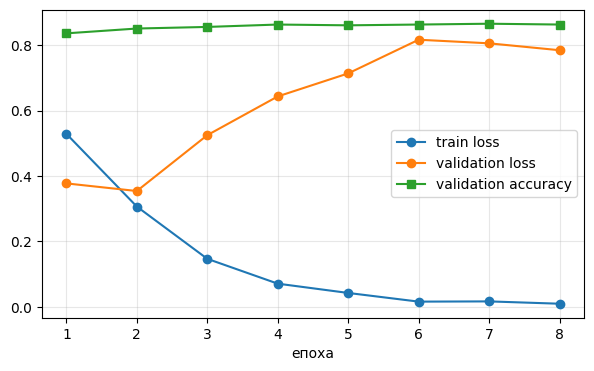

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(table["epoch"], table["loss"], marker="o", label="train loss")
plt.plot(table["epoch"], table["eval_loss"], marker="o", label="validation loss")
plt.plot(table["epoch"], table["eval_accuracy"], marker="s", label="validation accuracy")
plt.xlabel("епоха")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Відповіді на теоретичні питання (1–10)

### 1. Як довго виконувалися клітинки ноутбуку 01_bert_head? Чи були проблеми з запуском, які?

Час за індикатором `Trainer` на Tesla T4:
- донавчання на 3 епохи (690 кроків) — 1 хв 00 с, оцінка на валідації — менше 1 с;
- додатковий експеримент на 8 епох (1840 кроків) — 3 хв 52 с;
- решта клітинок (завантаження MRPC, `bert-base-uncased` ≈ 440 MB, токенізація) — секунди.

Проблеми:
- у першому запуску середовище Colab було без GPU (`'pin_memory' argument is set as true but no accelerator is found`): тренування йшло на CPU зі швидкістю 0.08 it/s, прогноз — 2 год 23 хв. Після вибору *Runtime → Change runtime type → T4 GPU* тривалість скоротилась до 1 хв;
- у доданій клітинці з власними прикладами була синтаксична помилка (перенос рядка всередині f-рядка), виправлено на `\n`;
- попередження `UNEXPECTED` / `MISSING` у звіті завантаження очікувані: це відкинута голова попереднього тренування і нова голова-класифікатор.

### 2. Як Ви розумієте, що таке токен [CLS]? Яким чином він виконує свою функцію?

`[CLS]` — службовий токен, який токенізатор ставить першим у кожну послідовність (`['[CLS]', 'revenue', 'in', ...]`). Власного змісту він не має. У кожному з 12 шарів self-attention його представлення обчислюється з урахуванням усіх токенів обох речень, тому на виході останнього шару вектор `[CLS]` (768 чисел) є зведеним представленням усієї пари.

Під час попереднього тренування BERT на цьому векторі вчився задачі next sentence prediction (голова `cls.seq_relationship`, позначена у звіті завантаження як `UNEXPECTED`). У `BertForSequenceClassification` вектор `[CLS]` проходить через pooler (лінійний шар + tanh) і нову голову `Linear(768, 2)`, яка дає логіти двох класів.

### 3. Яке пряме застосування базової моделі bert-base-uncased?

Модель натренована на двох задачах, і саме їх вона вміє виконувати без донавчання:
- **masked language modeling** — передбачення пропущеного слова `[MASK]` (у ноутбуці — `pipeline('fill-mask')`: «The man worked as a [MASK].» → carpenter 9.7 %, waiter 5.2 %, barber 5.0 %);
- **next sentence prediction** — чи є друге речення продовженням першого.

За карткою моделі основне призначення — бути кістяком для донавчання на задачах, що використовують усе речення: класифікація послідовностей, класифікація токенів (NER), відповіді на питання за текстом. Для генерації тексту модель не призначена: це енкодер без авторегресійного декодера.

### 4. Як Ви вважаєте, чи варто боротися (і якщо так, то яким чином) з проявами сексизму LLM-моделей?

Вивід у ноутбуці показує упередження явно: для «The man worked as a [MASK].» — carpenter, waiter, barber, mechanic, salesman; для «The woman worked as a [MASK].» — nurse (22.0 %), waitress (16.0 %), maid (11.5 %), prostitute (3.8 %), cook (3.0 %). Модель відтворює статистику корпусу (BookCorpus, англійська Вікіпедія), а не факти про людей.

Боротися варто, коли модель впливає на рішення щодо людей: відбір резюме, оцінка кандидатів, кредитний скоринг, модерація. Там упередження переходить у дискримінацію і юридичні ризики. Способи:
- аудит даних і їх балансування; counterfactual data augmentation — дублювання прикладів із заміною статі;
- вимірювання упереджень на тестових наборах (WinoBias, StereoSet, CrowS-Pairs) до і після донавчання;
- донавчання на збалансованих даних, вирівнювання (RLHF / DPO) з відповідними критеріями;
- виключення ознак статі з входу задачі, де вони не потрібні, і фільтрація виходу;
- людський контроль рішень і документування обмежень у картці моделі.

Повністю прибрати упередження неможливо, бо їх джерело — самі дані; мета — виміряти їх і не допустити впливу на рішення.

### 5. Для чого в секції "Токенізація пари речень" виводяться числа 0 і 1?

Це `token_type_ids` (segment ids): 0 — токени `[CLS]`, першого речення і першого `[SEP]`; 1 — токени другого речення і завершального `[SEP]`. У виводі перші 20 токенів мають 0, останні 20 — 1. Ці ідентифікатори перетворюються на segment embeddings і додаються до ембедингів токенів, тож модель розрізняє, до якого речення належить кожен токен. Для задачі парафраз це потрібно, щоб порівнювати два речення, а не читати їх як один текст.

### 6. Що позначають числа 768 і 2, що виводяться після завантаження AutoModelForSequenceClassification.from_pretrained()?

`Linear(in_features=768, out_features=2, bias=True)` — нова голова-класифікатор:
- **768** — розмірність прихованого стану BERT-base (hidden size), тобто довжина вектора `[CLS]` після pooler, який надходить на вхід голови;
- **2** — кількість виходів, задана `num_labels=2`: логіти класів `not_equivalent` (0) і `equivalent` (1).

Параметрів голови: 768 × 2 + 2 = 1 538, що збігається з виводом `count_params(model.classifier)`.

### 7. Те що в кістяку (backbone) набагато більше параметрів ніж в голові, це добре чи погано в нашому випадку?

Кістяк — 109 482 240 параметрів, голова — 1 538 (≈ 0.0014 %). Для нашої задачі це добре:
- знання мови (синтаксис, синоніми, порядок слів) уже містяться в кістяку після попереднього тренування; голові достатньо лінійно розділити готові представлення на два класи;
- випадково ініціалізовано лише 1 538 параметрів, тому їх вистачає 3 668 тренувальних пар і 1 хв тренування; з нуля модель такого розміру на цих даних не навчилася б.

Недолік з'являється при повному донавчанні: оновлюються всі 109 млн параметрів на 3.7 тис. прикладах, тому модель швидко запам'ятовує тренувальний набір (див. питання 9), а пам'ять потрібна на градієнти й стани оптимізатора для всього кістяка. Якщо даних ще менше, кістяк заморожують або використовують LoRA.

### 8. Що саме вимірюється за допомогою метрик accuracy & F1 в 01_bert_head?

Метрики рахуються у `compute_metrics` на валідаційному наборі MRPC (408 пар) після кожної епохи:
- **accuracy** — частка пар, для яких передбачений клас (argmax логітів) збігся з міткою; після 3 епох 0.860, тобто 351 з 408;
- **F1** — гармонійне середнє precision і recall для класу 1 (`equivalent`, `f1_score` за замовчуванням рахує позитивний клас); після 3 епох 0.902.

F1 потрібна, бо класи незбалансовані: у валідаційному наборі 279 з 408 пар (68.4 %) — парафрази. Модель, що завжди відповідає «парафраз», мала б accuracy 68.4 %, тому accuracy окремо не показує, наскільки модель розпізнає саме клас 1 і не дає хибних спрацювань.

### 9. Збільшіть кількість епох тренування в 01_bert_head, покажіть (скопіювавши результати) що відбувається і чому.

Розділ 6 ноутбука: та сама модель з нуля, 8 епох замість 3 (1840 кроків, 3 хв 52 с).

| Епоха | Train loss | Validation loss | Accuracy | F1 |
|---|---|---|---|---|
| 1 | 0.5287 | 0.3772 | 0.8358 | 0.8810 |
| 2 | 0.3064 | **0.3539** | 0.8505 | 0.8964 |
| 3 | 0.1467 | 0.5246 | 0.8554 | 0.8909 |
| 4 | 0.0708 | 0.6430 | 0.8627 | 0.9028 |
| 5 | 0.0424 | 0.7134 | 0.8603 | 0.9026 |
| 6 | 0.0159 | 0.8163 | 0.8627 | 0.9044 |
| 7 | 0.0166 | 0.8053 | **0.8652** | **0.9060** |
| 8 | 0.0095 | 0.7842 | 0.8627 | 0.9031 |

Що відбувається:
- train loss падає майже до нуля (0.53 → 0.0095): модель запам'ятовує 3 668 тренувальних пар;
- validation loss мінімальний після 2-ї епохи (0.354), далі зростає більш ніж удвічі (до 0.816) — класичне перенавчання;
- accuracy і F1 при цьому майже не змінюються: 0.855–0.865 і 0.89–0.91, приріст порівняно з 3 епохами — до 1 п. п.

Чому: на малому наборі модель із 109 млн параметрів підганяє ймовірності під тренувальні приклади і стає надмірно впевненою. На валідації кількість помилок майже та сама, але на помилкових прикладах модель тепер дає ймовірність, близьку до 0 або 1, і cross-entropy за них різко зростає. Додаткові епохи не покращують якість, а час тренування зростає в 3.9 раза. Для цієї задачі достатньо 2–3 епох; на практиці беруть модель з найменшим validation loss (`load_best_model_at_end=True`) або early stopping.

### 10. Додайте ще 4 перевірки на власних даних в пункті 4 в 01_bert_head.

Перевірки додано в розділ 5 ноутбука:

| Речення 1 | Речення 2 | Очікування | Модель |
|---|---|---|---|
| The meeting was moved to Friday afternoon. | The meeting will now take place on Friday after lunch. | парафраз | 97.5 % — правильно |
| He has lived in Kyiv for ten years. | He moved to Kyiv last month. | не парафраз | 34.3 % — правильно, але з невисокою впевненістю |
| The new phone has a larger screen and a better camera. | The latest phone model offers a bigger display and an improved camera. | парафраз | 99.1 % — правильно |
| Prices rose by 5 percent in October. | Prices fell by 5 percent in October. | не парафраз | 97.7 % — **помилка** |

Синоніми і перефразування модель розпізнає добре (97.5 %, 99.1 %). Остання пара відрізняється одним словом-антонімом, і модель вважає її парафразом: класифікатор значною мірою спирається на лексичний збіг, а в MRPC пари з майже однаковими словами здебільшого мають мітку «парафраз». Протилежний зміст при високому збігу слів — слабке місце моделі.